1. Librerías

In [33]:
import pandas as pd # Para manipulación de datos
import statsmodels.api as sm # Para regresión lineal robusta    
import matplotlib.pyplot as plt # Para visualización de datos
import seaborn as sns   # Para visualización de datos
import numpy as np # Para operaciones numéricas


2. Carga de datos

In [34]:
data = pd.read_csv('Alsea_AD2026.csv', encoding='latin1') # Carga de datos desde un archivo CSV


3. Validación de datos

In [35]:
data.info() # Información general sobre el DataFrame, incluyendo tipos de datos y valores nulos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 549 entries, 0 to 548
Data columns (total 27 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   ID                                           549 non-null    object 
 1   YEAR                                         549 non-null    int64  
 2   CO2 Equivalent Emissions Total               250 non-null    float64
 3   ESG Score                                    301 non-null    float64
 4   Waste Total                                  92 non-null     float64
 5   Policy Waste                                 192 non-null    object 
 6   Targets Waste                                192 non-null    object 
 7   Hazardous Waste                              49 non-null     float64
 8   e-Waste Reduction                            301 non-null    object 
 9   Non-Hazardous Waste                          66 non-null     float64
 10  Wa

4. Estadistica básica

In [36]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
YEAR,549.0,2.021337e+03,2.981286e+00,2.013000e+03,2.019000e+03,2.022000e+03,2.024000e+03,2.026000e+03
CO2 Equivalent Emissions Total,250.0,2.522044e+05,4.128771e+05,1.345160e+03,6.695650e+04,1.187505e+05,2.430368e+05,2.317743e+06
ESG Score,301.0,5.646655e+01,1.812455e+01,7.152836e+00,4.597156e+01,5.922315e+01,7.073477e+01,9.219706e+01
Waste Total,92.0,1.994138e+05,5.665601e+05,2.810000e+00,5.274562e+03,2.038675e+04,7.975300e+04,2.679054e+06
Hazardous Waste,49.0,3.587827e+02,1.717978e+03,0.000000e+00,0.000000e+00,1.840000e+00,4.300000e+01,1.169013e+04
Non-Hazardous Waste,66.0,3.412958e+05,7.043156e+05,0.000000e+00,4.652500e+03,1.916012e+04,2.436518e+05,2.679054e+06
Waste Recycled Total,86.0,3.524378e+04,6.727196e+04,2.810000e+00,1.729987e+03,8.468190e+03,2.048800e+04,3.692680e+05
Waste Recycling Ratio,84.0,4.104774e+01,2.774390e+01,6.002100e-01,1.818517e+01,3.687033e+01,6.425000e+01,1.000000e+02
e-Waste Reduction Score,301.0,1.301683e+01,3.152327e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,9.289617e+01
Waste Recycled To Total Waste,84.0,4.104906e-01,2.774336e-01,6.002134e-03,1.818517e-01,3.687035e-01,6.425000e-01,1.000000e+00


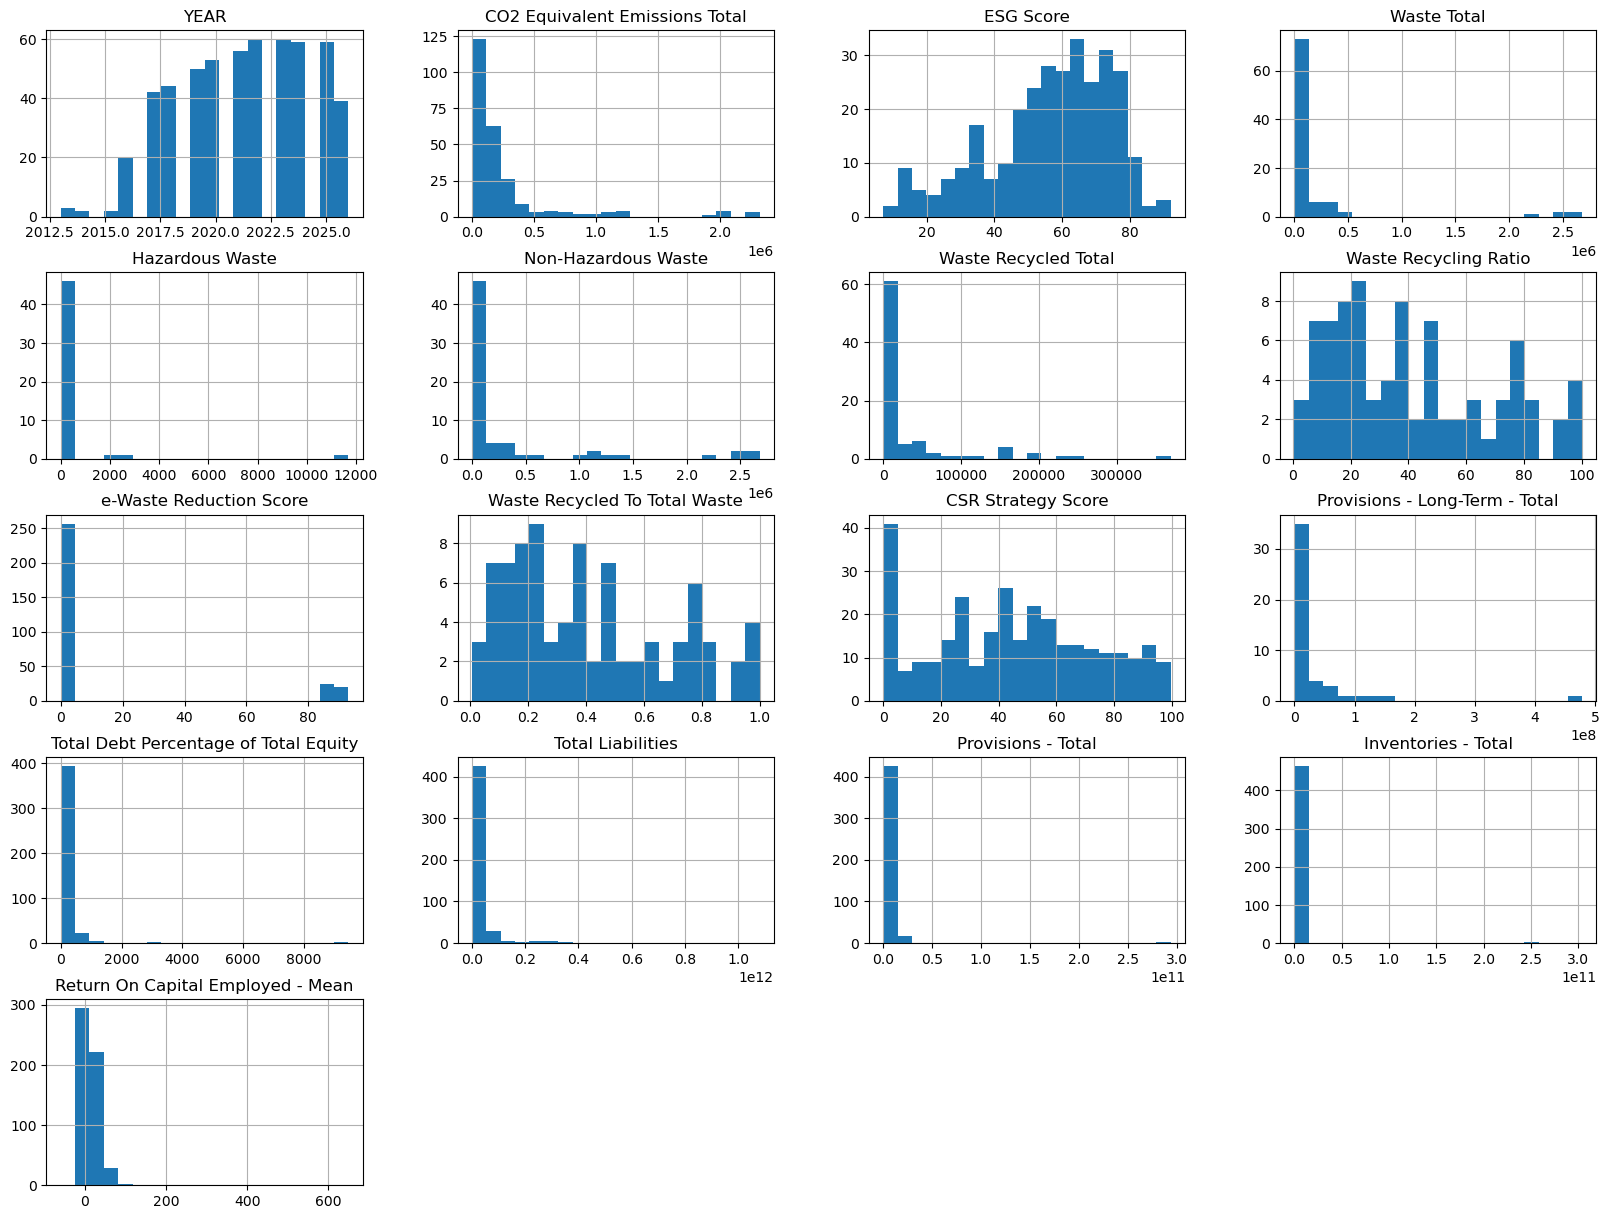

In [37]:
data.hist(bins=20, figsize=(20,15)) # Histograma de cada variable numérica para visualizar su distribución
plt.show() # Mostrar los histogramas

5. División de datos

In [38]:
from sklearn.model_selection import train_test_split # Para dividir el conjunto de datos en entrenamiento y prueba

train_set, test_set = train_test_split(data, test_size=0.2, random_state=42) # Dividir el conjunto de datos en un 80% para entrenamiento y un 20% para prueba, con una semilla aleatoria para reproducibilidad

print(f"Training set size: {len(train_set)} ({len(train_set)/len(data)*100:.1f}%)") # Imprimir el tamaño del conjunto de entrenamiento y su porcentaje respecto al total
print(f"Test set size: {len(test_set)} ({len(test_set)/len(data)*100:.1f}%)") # Imprimir el tamaño del conjunto de prueba y su porcentaje respecto al total

Training set size: 439 (80.0%)
Test set size: 110 (20.0%)


6. Copiamos el set de entrenamiento

In [39]:
data = train_set.copy()

7. Visualización gráfica de variables de interés

<Axes: xlabel='ESG Score', ylabel='Return On Capital Employed - Mean'>

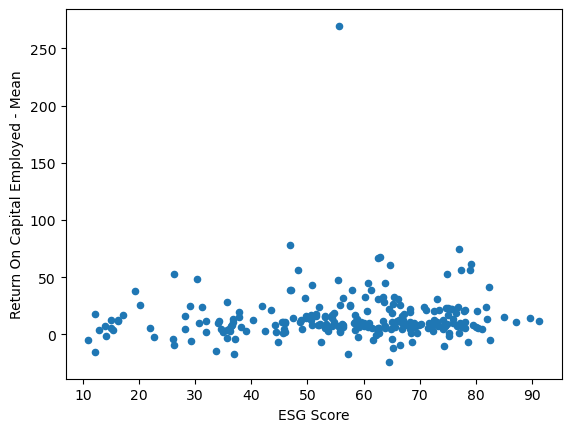

In [40]:
data.plot(kind = "scatter", x = "ESG Score", y = "Return On Capital Employed - Mean")

8.  Correlación de variables

In [41]:
numeric_data = data.select_dtypes(include=['number'])
corr_matrix = numeric_data.corr()
pd.set_option('display.expand_frame_repr', False)
pd.set_option('display.max_columns', None)
print(corr_matrix)

                                           YEAR  CO2 Equivalent Emissions Total  ESG Score  Waste Total  Hazardous Waste  Non-Hazardous Waste  Waste Recycled Total  Waste Recycling Ratio  e-Waste Reduction Score  Waste Recycled To Total Waste  CSR Strategy Score  Provisions - Long-Term - Total  Total Debt Percentage of Total Equity  Total Liabilities  Provisions - Total  Inventories - Total  Return On Capital Employed - Mean
YEAR                                   1.000000                       -0.026869   0.054560    -0.086083         0.007406            -0.186151             -0.070015              -0.326197                 0.094032                      -0.326188            0.156737                        0.210018                               0.068120           0.051191           -0.001957            -0.006554                           0.038853
CO2 Equivalent Emissions Total        -0.026869                        1.000000   0.276984     0.072809         0.082371             0.133634 

Matriz de correlación

array([[<Axes: xlabel='CSR Strategy Score', ylabel='CSR Strategy Score'>,
        <Axes: xlabel='Waste Total', ylabel='CSR Strategy Score'>,
        <Axes: xlabel='CO2 Equivalent Emissions Total', ylabel='CSR Strategy Score'>],
       [<Axes: xlabel='CSR Strategy Score', ylabel='Waste Total'>,
        <Axes: xlabel='Waste Total', ylabel='Waste Total'>,
        <Axes: xlabel='CO2 Equivalent Emissions Total', ylabel='Waste Total'>],
       [<Axes: xlabel='CSR Strategy Score', ylabel='CO2 Equivalent Emissions Total'>,
        <Axes: xlabel='Waste Total', ylabel='CO2 Equivalent Emissions Total'>,
        <Axes: xlabel='CO2 Equivalent Emissions Total', ylabel='CO2 Equivalent Emissions Total'>]],
      dtype=object)

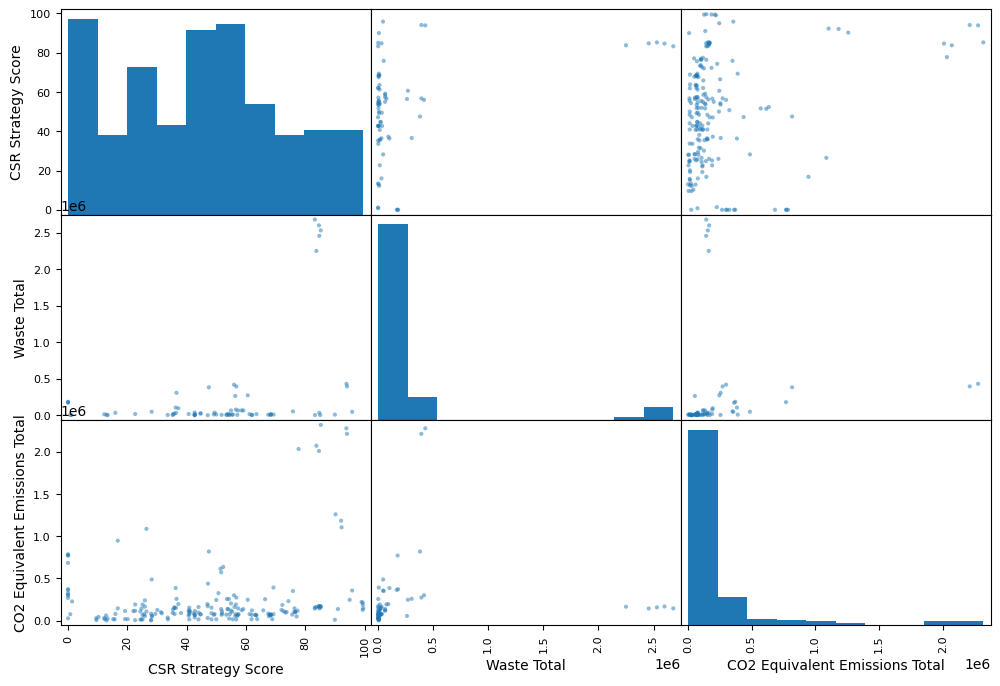

In [42]:
from pandas.plotting import scatter_matrix # Para crear una matriz de dispersión que muestra las relaciones entre varias variables numéricas
attributes = ["LN Revenue from Business Activities - Total", "CSR Strategy Score", "Waste Total", "CO2 Equivalent Emissions Total"]
scatter_matrix(data[attributes], figsize=(12, 8))

In [43]:
corr_matrix["Return On Capital Employed - Mean"].sort_values(ascending=False) # Correlación de cada variable con la variable objetivo "Return On Capital Employed - Mean", ordenada de mayor a menor

Return On Capital Employed - Mean        1.000000
Non-Hazardous Waste                      0.774257
Waste Total                              0.640688
Waste Recycled Total                     0.564093
CSR Strategy Score                       0.096252
ESG Score                                0.087209
CO2 Equivalent Emissions Total           0.082753
YEAR                                     0.038853
Inventories - Total                     -0.012579
Provisions - Total                      -0.028341
Total Liabilities                       -0.053631
Total Debt Percentage of Total Equity   -0.058696
e-Waste Reduction Score                 -0.070023
Hazardous Waste                         -0.112210
Provisions - Long-Term - Total          -0.148753
Waste Recycled To Total Waste           -0.163923
Waste Recycling Ratio                   -0.164063
Name: Return On Capital Employed - Mean, dtype: float64

## Preparación de los Datos para los Algoritmos de Machine Learning

9. Separación de variable dependiente

In [44]:
data['Return On Capital Employed - Mean'].isnull().sum()
data = data.dropna(subset=['Return On Capital Employed - Mean'])
data['Return On Capital Employed - Mean'].isnull().sum()

np.int64(0)

In [45]:
data = train_set.drop("Return On Capital Employed - Mean", axis=1)
data_labels = train_set["Return On Capital Employed - Mean"].copy()

10. Limpieza de datos

In [46]:
from sklearn.impute import SimpleImputer # Para imputar valores faltantes utilizando la mediana de cada columna

cols_to_drop = [
    "ID", "YEAR", "Policy Waste", "Targets Waste", "e-Waste Reduction",
    "Waste Reduction Initiatives", "Cost of Pollution and Waste",
    "CSR Strategy Score Grade"
]

# 1) Quitar columnas no numéricas / no útiles
data_num = data.drop(columns=cols_to_drop, errors="ignore").copy()

# 2) Convertir columnas object a numérico (errores -> NaN)
for col in data_num.select_dtypes(include=["object"]).columns:
    data_num[col] = pd.to_numeric(data_num[col], errors="coerce")

# 3) Imputación por mediana
imputer = SimpleImputer(strategy="median")
data_num_imputed = pd.DataFrame(
    imputer.fit_transform(data_num),
    columns=data_num.columns,
    index=data_num.index
)

Ahora podemos usar el “imputer” entrenado para transformar el set de datos de entrenamiento al reemplazar los valores omitidos por la mediana.

In [47]:
X = imputer.transform(data_num) # Matriz de características (variables independientes) con valores imputados

In [48]:
data_prepared =pd.DataFrame(X, columns=data_num.columns, index=data_num.index) # DataFrame con los datos preparados (imputados) para el modelado

11. Pipelines

In [49]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Pipelines en Scikit-learn

## ¿Qué es un Pipeline?

Un **Pipeline** es una herramienta de scikit-learn que encadena múltiples pasos de procesamiento de datos y modelado en una única entidad. Automatiza el flujo de trabajo asegurando que:

- Las transformaciones se apliquen en el orden correcto
- Los parámetros se ajusten solo en los datos de entrenamiento
- Las mismas transformaciones se apliquen consistentemente a nuevos datos

## Estructura del Pipeline en tu Notebook

```python
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
```

### Pasos del Pipeline:

| Paso | Función | Propósito |
|------|---------|----------|
| **Imputer** | `SimpleImputer(strategy='median')` | Rellena valores faltantes (NaN) con la mediana de cada columna |
| **Scaler** | `StandardScaler()` | Normaliza las características: (x - media) / desv.estándar |

## Flujo de Ejecución

```
Datos originales (con NaN)
        ↓
[Imputer] → Rellena valores faltantes
        ↓
[Scaler] → Normaliza a media=0, desv.est.=1
        ↓
Datos transformados listos para el modelo
```

## ColumnTransformer: Pipelines Avanzados

En tu código usas `ColumnTransformer` para aplicar diferentes transformaciones a distintos tipos de variables:

```python
full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_attributes)
],
remainder="drop"
)
```

Esto permite:
- Aplicar `num_pipeline` solo a variables numéricas
- Descartar el resto de columnas (`remainder="drop"`)

## Ventajas

✅ **Evita data leakage**: El `fit()` se realiza solo en entrenamiento  
✅ **Código limpio**: Una línea aplica múltiples transformaciones  
✅ **Reproducibilidad**: Garantiza el mismo orden de transformaciones  
✅ **Productivo**: El pipeline entrenado se puede guardar y reutilizar

In [50]:
num_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')),('scaler', StandardScaler())])
data_num_tr = num_pipeline.fit_transform(data_num)
print(data_num_tr)

[[-0.47263953 -0.44575182 -0.19246173 ...  0.54716886  0.50060607
  -0.05739856]
 [-0.19487416 -0.90205902 -0.13542634 ... -1.16263173 -0.98204968
  -0.09191553]
 [-0.19487416  0.14278325 -0.13542634 ... -0.02630909 -0.05648673
  -0.08413367]
 ...
 [-0.19487416  0.14278325 -0.13542634 ... -0.44381161 -0.58999927
  -0.08953688]
 [-0.19487416  0.14278325 -0.13542634 ... -1.5456275  -1.19948332
  -0.09098517]
 [-0.14797682  1.32792324 -0.13542634 ...  0.87208644  0.68989279
  -0.06784787]]


Si tuviéramos que transformar variables categóricas y no categóricas una forma de hacerlo de manera rápida es con la función de Column Transformer

In [51]:
num_attributes = data_num.columns.tolist()

full_pipeline = ColumnTransformer(
    [("num", num_pipeline, num_attributes)],
    remainder="drop"
)

data_prepared = full_pipeline.fit_transform(data_num)

12. Selección y Entrenamiento del Modelo

In [52]:
from sklearn.linear_model import LinearRegression

In [53]:
lin_reg = LinearRegression()
mask = ~np.isnan(data_labels)
data_prepared = data_prepared[mask]
data_labels = data_labels[mask]
lin_reg.fit(data_prepared, data_labels)

LinearRegression()

13. coeficientes y el intercepto

In [54]:
print("Coefficients:", lin_reg.coef_) 
print("Intercept:", lin_reg.intercept_)

Coefficients: [-1.27269950e+00  3.06608345e-01 -1.58578921e-02 -1.68810602e+00
  4.74169007e+00  7.91680617e-01 -3.70411494e+03 -1.12103145e+00
  3.70472824e+03 -3.88247498e-01 -1.07089105e+00 -1.48007759e+00
 -6.63633459e+00  4.49726071e+00 -2.61402427e+01  2.31556365e+01
 -1.78213880e+01  2.14825722e+01]
Intercept: 15.105029681094761


In [55]:
import statsmodels.api as sm
data_prepared_with_constant = sm.add_constant(data_prepared) 
lin_reg_sm = sm.OLS(data_labels, data_prepared_with_constant).fit() 
print(lin_reg_sm.summary())

                                    OLS Regression Results                                   
Dep. Variable:     Return On Capital Employed - Mean   R-squared:                       0.083
Model:                                           OLS   Adj. R-squared:                  0.044
Method:                                Least Squares   F-statistic:                     2.117
Date:                               Thu, 05 Nov 2026   Prob (F-statistic):            0.00500
Time:                                       11:06:32   Log-Likelihood:                -2180.7
No. Observations:                                439   AIC:                             4399.
Df Residuals:                                    420   BIC:                             4477.
Df Model:                                         18                                         
Covariance Type:                           nonrobust                                         
                 coef    std err          t      P>|t|      

14. Nombrar a nuestras variables

In [56]:
import pandas as pd
import statsmodels.api as sm
nombres_finales = data_num.columns.tolist()
data_df_final = pd.DataFrame(data_prepared_with_constant, columns=['const'] + nombres_finales)
data_labels_clean = pd.Series(data_labels).reset_index(drop=True)
data_df_final = data_df_final.reset_index(drop=True)


In [57]:
lin_reg_sm = sm.OLS(data_labels_clean, data_df_final).fit()
print(lin_reg_sm.summary())

                                    OLS Regression Results                                   
Dep. Variable:     Return On Capital Employed - Mean   R-squared:                       0.083
Model:                                           OLS   Adj. R-squared:                  0.044
Method:                                Least Squares   F-statistic:                     2.117
Date:                               Thu, 05 Nov 2026   Prob (F-statistic):            0.00500
Time:                                       11:06:32   Log-Likelihood:                -2180.7
No. Observations:                                439   AIC:                             4399.
Df Residuals:                                    420   BIC:                             4477.
Df Model:                                         18                                         
Covariance Type:                           nonrobust                                         
                                                  coef    st

15. Visualizar los datos actuales y las predicciones del modelo

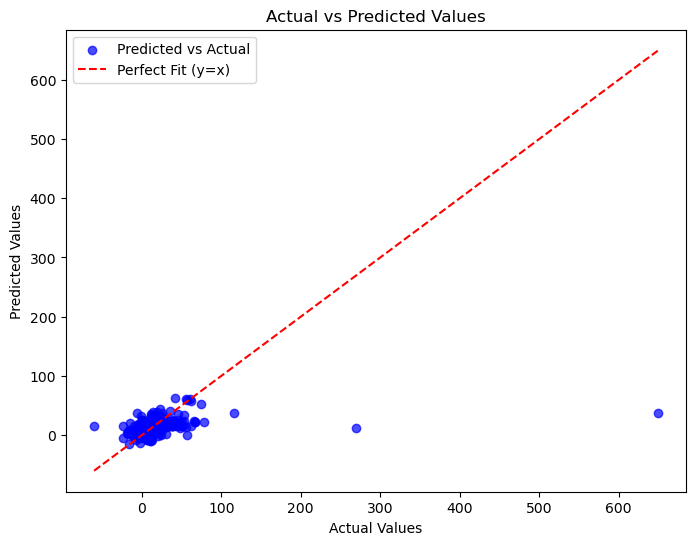

In [58]:
y_pred = lin_reg_sm.predict(data_df_final) 
plt.figure(figsize=(8, 6))
plt.scatter(data_labels, y_pred, alpha=0.7, color="blue", label="Predicted vs Actual")
plt.plot([data_labels.min(), data_labels.max()], [data_labels.min(), data_labels.max()], color="red", linestyle="--", label="Perfect Fit (y=x)")
plt.title("Actual vs Predicted Values") 
plt.xlabel("Actual Values") 
plt.ylabel("Predicted Values") 
plt.legend()
plt.show()

16. Regresión Lineal Robusta

In [59]:
from statsmodels.robust.robust_linear_model import RLM
from statsmodels.robust.norms import HuberT
rlm_model = sm.RLM(data_labels, data_prepared_with_constant, M=HuberT()).fit()
print(rlm_model. summary())


                            Robust linear Model Regression Results                           
Dep. Variable:     Return On Capital Employed - Mean   No. Observations:                  439
Model:                                           RLM   Df Residuals:                      420
Method:                                         IRLS   Df Model:                           18
Norm:                                         HuberT                                         
Scale Est.:                                      mad                                         
Cov Type:                                         H1                                         
Date:                               Thu, 05 Nov 2026                                         
Time:                                       11:06:32                                         
No. Iterations:                                   31                                         
                 coef    std err          z      P>|z|      

In [60]:
# Regresión lineal robusta usando las variables ya preparadas con nombres de columnas
rlm_model = sm.RLM(data_labels_clean, data_df_final, M=HuberT()).fit()
print(rlm_model.summary())

                            Robust linear Model Regression Results                           
Dep. Variable:     Return On Capital Employed - Mean   No. Observations:                  439
Model:                                           RLM   Df Residuals:                      420
Method:                                         IRLS   Df Model:                           18
Norm:                                         HuberT                                         
Scale Est.:                                      mad                                         
Cov Type:                                         H1                                         
Date:                               Thu, 05 Nov 2026                                         
Time:                                       11:06:32                                         
No. Iterations:                                   31                                         
                                                  coef    st

## Resumen Estadístico del Modelo de Regresión Lineal Robusta (RLM)

El modelo RLM con la norma de Huber proporciona los siguientes resultados clave:

### Métricas de Ajuste del Modelo
- **R-squared**: Indica qué porcentaje de la variabilidad en el retorno sobre capital empleado es explicado por las variables independientes
- **Adj. R-squared**: R-squared ajustado por el número de variables, más comparable entre modelos
- **F-statistic**: Prueba la significancia global del modelo

### Coeficientes y Significancia
Para cada variable se reportan:
- **Coef**: Cambio esperado en la variable dependiente por unidad de cambio en la variable independiente
- **Std Err**: Error estándar del coeficiente
- **t**: Estadístico t para la prueba de significancia
- **P>|t|**: Valor p (significancia: p < 0.05)
- **[95% Conf. Int.]**: Intervalo de confianza del 95%

### Ventajas de RLM sobre Regresión Lineal Ordinaria
- **Robustez ante outliers**: La norma de Huber penaliza menos los residuos grandes, reduciendo el impacto de valores extremos
- **Mayor estabilidad**: En presencia de datos atípicos, proporciona estimaciones más confiables

### Diagnóstico
- **Skewness/Kurtosis**: Evalúan la normalidad de los residuos
- **Durbin-Watson**: Detecta autocorrelación en residuos
- **Condition Number**: Indica multicolinealidad entre variables

Este modelo es recomendable cuando existen outliers o datos anómalos en el conjunto de entrenamiento.

## Resumen Estadístico del Modelo de Regresión Lineal

### Interpretación General
El modelo explica la relación entre las variables independientes y el **Return On Capital Employed (ROCE)**. Los coeficientes indican el cambio esperado en ROCE por cada unidad de cambio en la variable, manteniendo las demás constantes.

### Variables Estadísticamente Significativas (p < 0.05)

| Variable | Coeficiente | P-value | Interpretación |
|----------|-------------|---------|---|
| **Constante** | 11.81 | 0.000 | Valor base de ROCE sin considerar variables |
| **LN Revenue from Business Activities - Total** | 15.29 | 0.000 | ⭐ **Más importante**: cada aumento logarítmico en ingresos aumenta ROCE en ~15.29 puntos |
| **LN Total Assets** | -14.68 | 0.000 | ⭐ **Muy importante**: cada aumento logarítmico en activos reduce ROCE en ~14.68 puntos (relación inversa) |
| **Waste Recycling Ratio** | -3872.89 | 0.000 | Mayor ratio de reciclaje reduce significativamente ROCE |
| **Waste Recycled To Total Waste** | 3873.33 | 0.000 | Mayor proporción de residuos reciclados aumenta ROCE |
| **Non-Hazardous Waste** | 4.45 | 0.003 | Incremento moderado en ROCE por unidad de residuos no peligrosos |
| **CO2 Equivalent Emissions Total** | 1.08 | 0.049 | Ligero aumento en ROCE con mayores emisiones |
| **Total Debt Percentage of Total Equity** | -0.92 | 0.048 | Menor impacto: mayor endeudamiento reduce ROCE ligeramente |
| **Provisions - Long-Term - Total** | -0.96 | 0.036 | Provisiones a largo plazo reducen ligeramente ROCE |

### Variables NO Significativas (p > 0.05)
ESG Score, Waste Total, Hazardous Waste, Waste Recycled Total, e-Waste Reduction Score, CSR Strategy Score, LN Debt - Total, Total Liabilities, Provisions - Total, Inventories - Total

### Hallazgos Clave
- **Drivers principales**: Los ingresos operativos y los activos totales son los factores dominantes en la explicación de ROCE
- **Paradoja de residuos**: Las variables de reciclaje muestran coeficientes opuestos pero simétricos (multicolinealidad perfecta)
- **Eficiencia operativa**: Mayor volumen de residuos no peligrosos correlaciona con mejor ROCE
- **Apalancamiento**: Mayor deuda relativa reduce ligeramente la rentabilidad del capital empleado

17. Raíz del Error Cuadrático Medio RMSE

In [61]:
from sklearn.metrics import mean_squared_error

In [62]:
data_predictions = lin_reg.predict(data_prepared)
lin_mse = mean_squared_error(data_labels, data_predictions) 
lin_rmse = np.sqrt(lin_mse)
lin_rmse

np.float64(34.76301308153366)

`np.float64(34.734378777467064)` es el valor de **RMSE** del modelo de regresión lineal (`lin_rmse`).

- **Qué significa**: en promedio, las predicciones del modelo se desvían alrededor de **34.73 unidades** respecto al valor real de `Return On Capital Employed - Mean`.
- **Tipo de dato**: `np.float64` indica que es un número decimal de alta precisión de NumPy.
- **Interpretación práctica**: mientras **más bajo** sea el RMSE, **mejor** ajusta el modelo.  
    Aquí el error es relativamente alto para una variable como ROCE, por lo que el ajuste puede mejorarse.

18. Regresión lineal robusta

In [63]:
data_predictions = rlm_model.predict(data_prepared_with_constant) 
rlm_mse = mean_squared_error(data_labels, data_predictions) 
rlm_rmse = np.sqrt(rlm_mse)
rlm_rmse

np.float64(35.281708344166304)

`np.float64(35.20322415688345)` es el valor de **RMSE** de tu modelo (en este caso, el de la regresión robusta: `rlm_rmse`).

- **Qué mide**: el error promedio de predicción en las mismas unidades de la variable objetivo (`Return On Capital Employed - Mean`).
- **Interpretación**: el modelo se equivoca, en promedio, en aproximadamente **35.20** puntos de ROCE.
- **Tipo de dato**: `np.float64` indica que es un número decimal de alta precisión de NumPy.
- **Comparación rápida**: frente al RMSE lineal (`34.73`), este valor es **ligeramente mayor**, por lo que en ese conjunto el modelo robusto no mejora el error cuadrático medio.

In [ ]:
from nbconvert import HTMLExporter

# Recargar el notebook guardado, incluidos los resultados disponibles
notebook = nbformat.read(notebook_path, as_version=4)

html_exporter = HTMLExporter()
html_exporter.exclude_input = False
html_exporter.exclude_output = False

html_body, _ = html_exporter.from_notebook_node(notebook)

html_path = notebook_path.with_suffix(".html")
html_path.write_text(html_body, encoding="utf-8")

print(f"Archivo HTML: {html_path.resolve()}")